# Priority 2 — Problem-Level Consistency Analysis

**What this does:**
Classifies each of the 50 GSM8K test problems by how it behaves
across bit-widths and decoding strategies. Identifies:
- Robust problems: correct at all bit-widths
- Fragile problems: correct at BF16 but fail under quantization
- SC-hurt problems: greedy correct but SC makes it wrong
- Already wrong: fails at all configurations
- Self-corrected: SC fixes what greedy got wrong

**No GPU needed — runs entirely on your laptop.**

**Required files in `all_results/` folder (same as Priority 1):**
- qwen2_gsm8k_bf16.csv
- qwen2_gsm8k_w8a16.csv
- qwen2_gsm8k_w4a16.csv
- llama_gsm8k_b16.csv
- llama_gsm8k_w8a16.csv
- llama_gsm8k_w4a16.csv

**Outputs saved to `consistency_outputs/`:**
- problem_categories.pdf/png
- sc_effect_by_bitwidth.pdf/png
- cross_model_consistency.pdf/png
- problem_consistency_full.csv

In [1]:
pip install pandas matplotlib numpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# ── CELL 1: Imports ────────────────────────────────────────────────────────────

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import os

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 150

DATA_DIR   = 'all_results'
OUTPUT_DIR = 'consistency_outputs'
os.makedirs(OUTPUT_DIR, exist_ok=True)
print('Imports OK')

Imports OK


In [3]:
# ── CELL 2: Load all CSVs ──────────────────────────────────────────────────────

qwen2 = {
    'BF16':  pd.read_csv(f'{DATA_DIR}/qwen2_gsm8k_bf16.csv'),
    'W8A16': pd.read_csv(f'{DATA_DIR}/qwen2_gsm8k_w8a16.csv'),
    'W4A16': pd.read_csv(f'{DATA_DIR}/qwen2_gsm8k_w4a16.csv'),
}
llama = {
    'BF16':  pd.read_csv(f'{DATA_DIR}/llama_gsm8k_b16.csv'),
    'W8A16': pd.read_csv(f'{DATA_DIR}/llama_gsm8k_w8a16.csv'),
    'W4A16': pd.read_csv(f'{DATA_DIR}/llama_gsm8k_w4a16.csv'),
}

for bw, df in qwen2.items():
    print(f'Qwen2 {bw}: {df.shape} | strategies: {df["decoding_strategy"].unique().tolist()}')
print()
for bw, df in llama.items():
    print(f'LLaMA {bw}: {df.shape} | strategies: {df["decoding_strategy"].unique().tolist()}')

Qwen2 BF16: (100, 11) | strategies: ['greedy', 'self_consistency']
Qwen2 W8A16: (100, 11) | strategies: ['greedy', 'self_consistency']
Qwen2 W4A16: (100, 11) | strategies: ['greedy', 'self_consistency']

LLaMA BF16: (100, 11) | strategies: ['greedy', 'self_consistency']
LLaMA W8A16: (100, 11) | strategies: ['greedy', 'self_consistency']
LLaMA W4A16: (100, 11) | strategies: ['greedy', 'self_consistency']


In [4]:
# ── CELL 3: Build problem-level pivot table ────────────────────────────────────
# For each problem_id, get correct/incorrect for every
# combination of bit-width and decoding strategy
# This gives us one row per problem with all configurations as columns

def build_pivot(model_data, model_name):
    """
    Build a wide-format table: one row per problem,
    columns = (bitwidth, strategy) combinations.
    """
    frames = []
    for bw, df in model_data.items():
        for strat in df['decoding_strategy'].unique():
            sub = df[df['decoding_strategy'] == strat][['problem_id', 'difficulty', 'correct']].copy()
            sub = sub.rename(columns={'correct': f'{bw}_{strat}'})
            frames.append(sub.set_index(['problem_id', 'difficulty']))

    pivot = pd.concat(frames, axis=1).reset_index()
    pivot['model'] = model_name
    return pivot

qwen2_pivot = build_pivot(qwen2, 'Qwen2')
llama_pivot = build_pivot(llama, 'LLaMA')

print('Qwen2 pivot columns:', qwen2_pivot.columns.tolist())
print(f'Qwen2 pivot shape:   {qwen2_pivot.shape}')
print()
print('LLaMA pivot columns:', llama_pivot.columns.tolist())
print(f'LLaMA pivot shape:   {llama_pivot.shape}')

Qwen2 pivot columns: ['problem_id', 'difficulty', 'BF16_greedy', 'BF16_self_consistency', 'W8A16_greedy', 'W8A16_self_consistency', 'W4A16_greedy', 'W4A16_self_consistency', 'model']
Qwen2 pivot shape:   (50, 9)

LLaMA pivot columns: ['problem_id', 'difficulty', 'BF16_greedy', 'BF16_self_consistency', 'W8A16_greedy', 'W8A16_self_consistency', 'W4A16_greedy', 'W4A16_self_consistency', 'model']
LLaMA pivot shape:   (50, 9)


In [5]:
# ── CELL 4: Classify each problem — Qwen2 ─────────────────────────────────────
# Categories based on greedy performance across bit-widths:
#
# ROBUST:       correct at BF16 greedy AND W8A16 greedy AND W4A16 greedy
# FRAGILE_W8:   correct BF16 greedy, wrong W8A16 greedy
# FRAGILE_W4:   correct BF16 greedy, correct W8A16 greedy, wrong W4A16 greedy
# ALREADY_WRONG: wrong at BF16 greedy (model cannot solve regardless)
# IMPROVED_Q:   wrong BF16 greedy but correct at quantized (unusual)
#
# SC effect categories (per bit-width):
# SC_HELPED:    wrong greedy → correct SC
# SC_HURT:      correct greedy → wrong SC
# SC_NEUTRAL:   same result with greedy and SC

def classify_qwen2(row):
    bf16_g  = row.get('BF16_greedy', False)
    w8_g    = row.get('W8A16_greedy', False)
    w4_g    = row.get('W4A16_greedy', False)

    if bf16_g and w8_g and w4_g:
        return 'Robust'
    elif not bf16_g and not w8_g and not w4_g:
        return 'Always Wrong'
    elif bf16_g and w8_g and not w4_g:
        return 'Fragile at W4A16'
    elif bf16_g and not w8_g:
        return 'Fragile at W8A16'
    elif not bf16_g and (w8_g or w4_g):
        return 'Improved by Quantization'
    else:
        return 'Mixed'

qwen2_pivot['greedy_category'] = qwen2_pivot.apply(classify_qwen2, axis=1)

print('Qwen2 greedy category distribution:')
cat_counts = qwen2_pivot['greedy_category'].value_counts()
for cat, count in cat_counts.items():
    print(f'  {cat:<30}: {count:3d} problems ({count/len(qwen2_pivot)*100:.1f}%)')

print()
print('By difficulty:')
print(pd.crosstab(qwen2_pivot['difficulty'], qwen2_pivot['greedy_category']))

Qwen2 greedy category distribution:
  Always Wrong                  :  19 problems (38.0%)
  Robust                        :  15 problems (30.0%)
  Improved by Quantization      :  10 problems (20.0%)
  Fragile at W8A16              :   3 problems (6.0%)
  Fragile at W4A16              :   3 problems (6.0%)

By difficulty:
greedy_category  Always Wrong  Fragile at W4A16  Fragile at W8A16  \
difficulty                                                          
easy                        8                 1                 1   
hard                        6                 1                 0   
medium                      5                 1                 2   

greedy_category  Improved by Quantization  Robust  
difficulty                                         
easy                                    4       6  
hard                                    1       2  
medium                                  5       7  


In [6]:
# ── CELL 5: SC effect analysis per bit-width — Qwen2 ──────────────────────────
# For each bit-width, count how many problems SC helped vs hurt vs neutral

def sc_effect(row, bw):
    greedy = row.get(f'{bw}_greedy', False)
    sc     = row.get(f'{bw}_self_consistency', False)
    if not greedy and sc:
        return 'SC Helped'
    elif greedy and not sc:
        return 'SC Hurt'
    elif greedy and sc:
        return 'Both Correct'
    else:
        return 'Both Wrong'

print('Qwen2 SC effect per bit-width:')
print(f'{"":<20} {"BF16":>12} {"W8A16":>12} {"W4A16":>12}')
print('-'*58)

sc_summary = {}
for bw in ['BF16', 'W8A16', 'W4A16']:
    qwen2_pivot[f'sc_effect_{bw}'] = qwen2_pivot.apply(
        lambda r: sc_effect(r, bw), axis=1
    )
    sc_summary[bw] = qwen2_pivot[f'sc_effect_{bw}'].value_counts()

for effect in ['SC Helped', 'SC Hurt', 'Both Correct', 'Both Wrong']:
    row_vals = [sc_summary[bw].get(effect, 0) for bw in ['BF16', 'W8A16', 'W4A16']]
    print(f'{effect:<20} {row_vals[0]:>12} {row_vals[1]:>12} {row_vals[2]:>12}')

print()
print('Key: SC Hurt problems at W4A16 are the systematic error signature')
print('     Correct greedy → wrong SC means voting amplified the wrong answer')

Qwen2 SC effect per bit-width:
                             BF16        W8A16        W4A16
----------------------------------------------------------
SC Helped                       8            5            4
SC Hurt                         1            2           10
Both Correct                   20           21           15
Both Wrong                     21           22           21

Key: SC Hurt problems at W4A16 are the systematic error signature
     Correct greedy → wrong SC means voting amplified the wrong answer


In [7]:
# ── CELL 6: Same SC effect for LLaMA ──────────────────────────────────────────

print('LLaMA SC effect per bit-width:')
print(f'{"":<20} {"BF16":>12} {"W8A16":>12} {"W4A16":>12}')
print('-'*58)

llama_sc_summary = {}
for bw in ['BF16', 'W8A16', 'W4A16']:
    llama_pivot[f'sc_effect_{bw}'] = llama_pivot.apply(
        lambda r: sc_effect(r, bw), axis=1
    )
    llama_sc_summary[bw] = llama_pivot[f'sc_effect_{bw}'].value_counts()

for effect in ['SC Helped', 'SC Hurt', 'Both Correct', 'Both Wrong']:
    row_vals = [llama_sc_summary[bw].get(effect, 0) for bw in ['BF16', 'W8A16', 'W4A16']]
    print(f'{effect:<20} {row_vals[0]:>12} {row_vals[1]:>12} {row_vals[2]:>12}')

print()
print('Compare with Qwen2 above:')
print('  LLaMA SC Hurt should be low across all bit-widths')
print('  Qwen2 SC Hurt should increase at W4A16')

LLaMA SC effect per bit-width:
                             BF16        W8A16        W4A16
----------------------------------------------------------
SC Helped                       9            7            9
SC Hurt                         2            2            0
Both Correct                   32           34           33
Both Wrong                      7            7            8

Compare with Qwen2 above:
  LLaMA SC Hurt should be low across all bit-widths
  Qwen2 SC Hurt should increase at W4A16


C:\Users\Admin\AppData\Local\Temp\ipykernel_4752\1253127663.py:24: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(present, rotation=15, ha='right', fontsize=9)


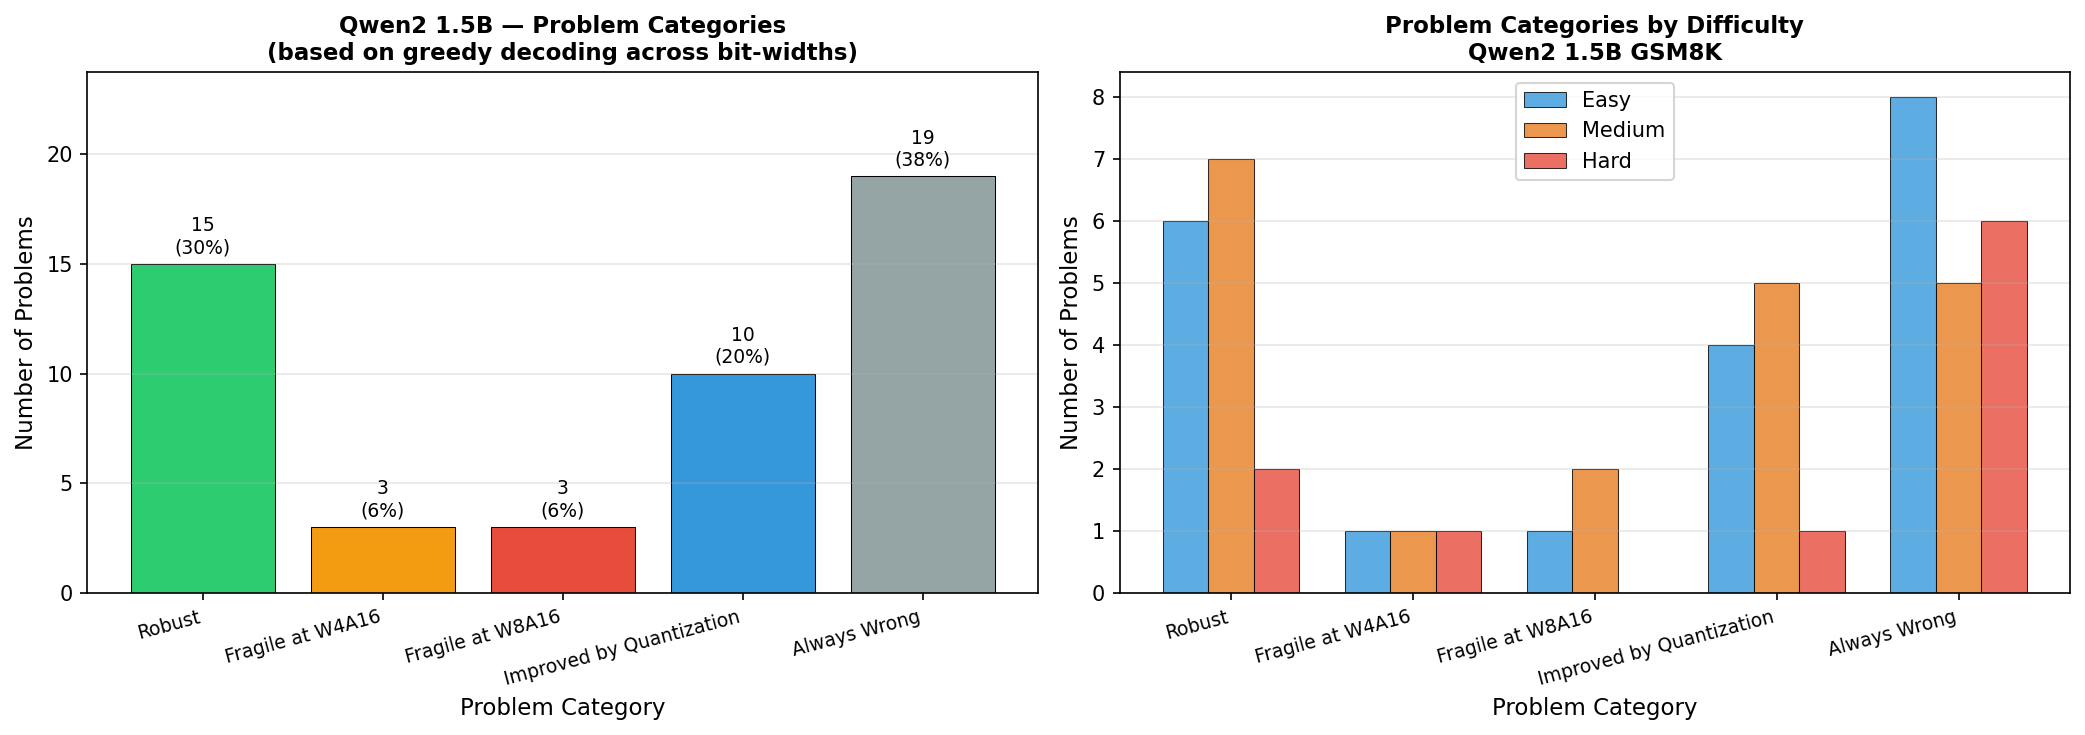

Figure saved


In [8]:
# ── CELL 7: Problem category bar chart — Qwen2 ───────────────────────────────
# Shows the distribution of problem categories as a stacked bar

cat_order  = ['Robust', 'Fragile at W4A16', 'Fragile at W8A16',
               'Improved by Quantization', 'Mixed', 'Always Wrong']
cat_colors = ['#2ecc71', '#f39c12', '#e74c3c', '#3498db', '#9b59b6', '#95a5a6']

cat_counts = qwen2_pivot['greedy_category'].value_counts()
present    = [c for c in cat_order if c in cat_counts.index]
counts     = [cat_counts.get(c, 0) for c in present]
colors     = [cat_colors[cat_order.index(c)] for c in present]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: overall distribution
bars = axes[0].bar(present, counts, color=colors, edgecolor='black', linewidth=0.5)
for bar, count in zip(bars, counts):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                 f'{count}\n({count/50*100:.0f}%)', ha='center', va='bottom', fontsize=9)
axes[0].set_xlabel('Problem Category', fontsize=11)
axes[0].set_ylabel('Number of Problems', fontsize=11)
axes[0].set_title('Qwen2 1.5B — Problem Categories\n(based on greedy decoding across bit-widths)',
                   fontsize=11, fontweight='bold')
axes[0].set_xticklabels(present, rotation=15, ha='right', fontsize=9)
axes[0].set_ylim(0, max(counts) * 1.25)
axes[0].grid(True, alpha=0.3, axis='y')

# Right: breakdown by difficulty
diff_order  = ['easy', 'medium', 'hard']
diff_colors = ['#3498db', '#e67e22', '#e74c3c']
x = np.arange(len(present))
width = 0.25

for j, (diff, color) in enumerate(zip(diff_order, diff_colors)):
    diff_counts = []
    for cat in present:
        n = len(qwen2_pivot[
            (qwen2_pivot['greedy_category'] == cat) &
            (qwen2_pivot['difficulty'] == diff)
        ])
        diff_counts.append(n)
    axes[1].bar(x + j*width, diff_counts, width, label=diff.capitalize(),
                color=color, alpha=0.8, edgecolor='black', linewidth=0.5)

axes[1].set_xlabel('Problem Category', fontsize=11)
axes[1].set_ylabel('Number of Problems', fontsize=11)
axes[1].set_title('Problem Categories by Difficulty\nQwen2 1.5B GSM8K',
                   fontsize=11, fontweight='bold')
axes[1].set_xticks(x + width)
axes[1].set_xticklabels(present, rotation=15, ha='right', fontsize=9)
axes[1].legend(fontsize=10)
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/problem_categories.pdf', dpi=300, bbox_inches='tight')
plt.savefig(f'{OUTPUT_DIR}/problem_categories.png', dpi=300, bbox_inches='tight')
plt.show()
print('Figure saved')

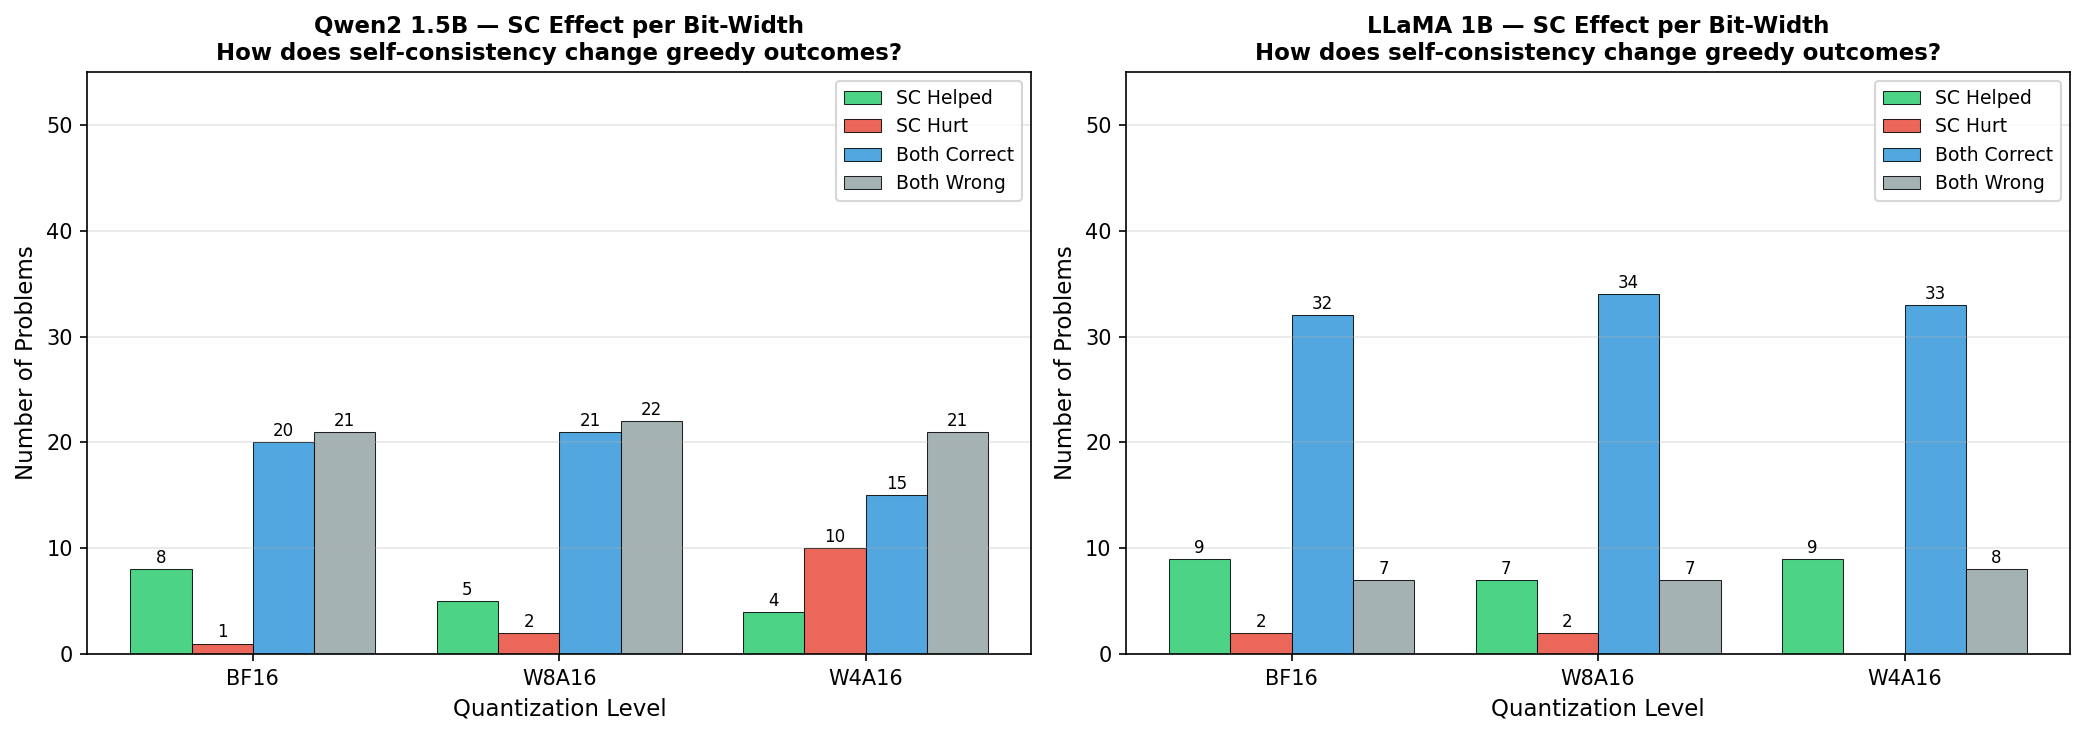

Figure saved


In [9]:
# ── CELL 8: SC effect comparison — Qwen2 vs LLaMA ─────────────────────────────
# Side by side: how many problems does SC hurt at each bit-width
# for each model — this is the core cross-model SC comparison

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
bitwidths  = ['BF16', 'W8A16', 'W4A16']
effects    = ['SC Helped', 'SC Hurt', 'Both Correct', 'Both Wrong']
eff_colors = ['#2ecc71', '#e74c3c', '#3498db', '#95a5a6']
x          = np.arange(len(bitwidths))
width      = 0.2

for ax, (model_sum, model_name) in zip(axes, [
    (sc_summary, 'Qwen2 1.5B'),
    (llama_sc_summary, 'LLaMA 1B')
]):
    for j, (eff, color) in enumerate(zip(effects, eff_colors)):
        counts = [model_sum[bw].get(eff, 0) for bw in bitwidths]
        bars = ax.bar(x + j*width, counts, width, label=eff,
                      color=color, alpha=0.85, edgecolor='black', linewidth=0.5)
        for bar, count in zip(bars, counts):
            if count > 0:
                ax.text(bar.get_x() + bar.get_width()/2,
                        bar.get_height() + 0.2,
                        str(count), ha='center', va='bottom', fontsize=8)

    ax.set_xticks(x + width * 1.5)
    ax.set_xticklabels(bitwidths, fontsize=10)
    ax.set_xlabel('Quantization Level', fontsize=11)
    ax.set_ylabel('Number of Problems', fontsize=11)
    ax.set_title(f'{model_name} — SC Effect per Bit-Width\n'
                 f'How does self-consistency change greedy outcomes?',
                 fontsize=11, fontweight='bold')
    ax.legend(fontsize=9, loc='upper right')
    ax.grid(True, alpha=0.3, axis='y')
    ax.set_ylim(0, 55)

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/sc_effect_by_bitwidth.pdf', dpi=300, bbox_inches='tight')
plt.savefig(f'{OUTPUT_DIR}/sc_effect_by_bitwidth.png', dpi=300, bbox_inches='tight')
plt.show()
print('Figure saved')

In [10]:
# ── CELL 9: Cross-model consistency comparison ─────────────────────────────────
# For each problem: is it consistently correct across models and bit-widths?
# Merge Qwen2 and LLaMA pivots on problem_id to compare

# Get greedy correct columns for both models
q_greedy = qwen2_pivot[['problem_id', 'difficulty',
                          'BF16_greedy', 'W8A16_greedy', 'W4A16_greedy',
                          'greedy_category']].copy()
q_greedy.columns = ['problem_id', 'difficulty',
                     'Q_BF16', 'Q_W8A16', 'Q_W4A16', 'Q_category']

l_greedy = llama_pivot[['problem_id',
                          'BF16_greedy', 'W8A16_greedy', 'W4A16_greedy']].copy()
l_greedy.columns = ['problem_id', 'L_BF16', 'L_W8A16', 'L_W4A16']

merged = q_greedy.merge(l_greedy, on='problem_id')

# Cross-model categories
def cross_model_cat(row):
    q_any = any([row['Q_BF16'], row['Q_W8A16'], row['Q_W4A16']])
    l_any = any([row['L_BF16'], row['L_W8A16'], row['L_W4A16']])
    q_all = all([row['Q_BF16'], row['Q_W8A16'], row['Q_W4A16']])
    l_all = all([row['L_BF16'], row['L_W8A16'], row['L_W4A16']])

    if q_all and l_all:
        return 'Both always correct'
    elif not q_any and not l_any:
        return 'Both always wrong'
    elif q_all and not l_all:
        return 'Qwen2 robust, LLaMA fragile'
    elif l_all and not q_all:
        return 'LLaMA robust, Qwen2 fragile'
    elif q_any and l_any:
        return 'Both partially correct'
    elif q_any and not l_any:
        return 'Only Qwen2 correct'
    else:
        return 'Only LLaMA correct'

merged['cross_model_category'] = merged.apply(cross_model_cat, axis=1)

print('Cross-model consistency:')
cross_counts = merged['cross_model_category'].value_counts()
for cat, count in cross_counts.items():
    print(f'  {cat:<35}: {count:3d} ({count/len(merged)*100:.1f}%)')

print()
print('By difficulty:')
print(pd.crosstab(merged['difficulty'], merged['cross_model_category']))

Cross-model consistency:
  Both always correct                :  14 (28.0%)
  LLaMA robust, Qwen2 fragile        :  12 (24.0%)
  Both partially correct             :   8 (16.0%)
  Only LLaMA correct                 :   8 (16.0%)
  Both always wrong                  :   5 (10.0%)
  Only Qwen2 correct                 :   2 (4.0%)
  Qwen2 robust, LLaMA fragile        :   1 (2.0%)

By difficulty:
cross_model_category  Both always correct  Both always wrong  \
difficulty                                                     
easy                                    6                  1   
hard                                    2                  1   
medium                                  6                  3   

cross_model_category  Both partially correct  LLaMA robust, Qwen2 fragile  \
difficulty                                                                  
easy                                       5                            3   
hard                                       1        

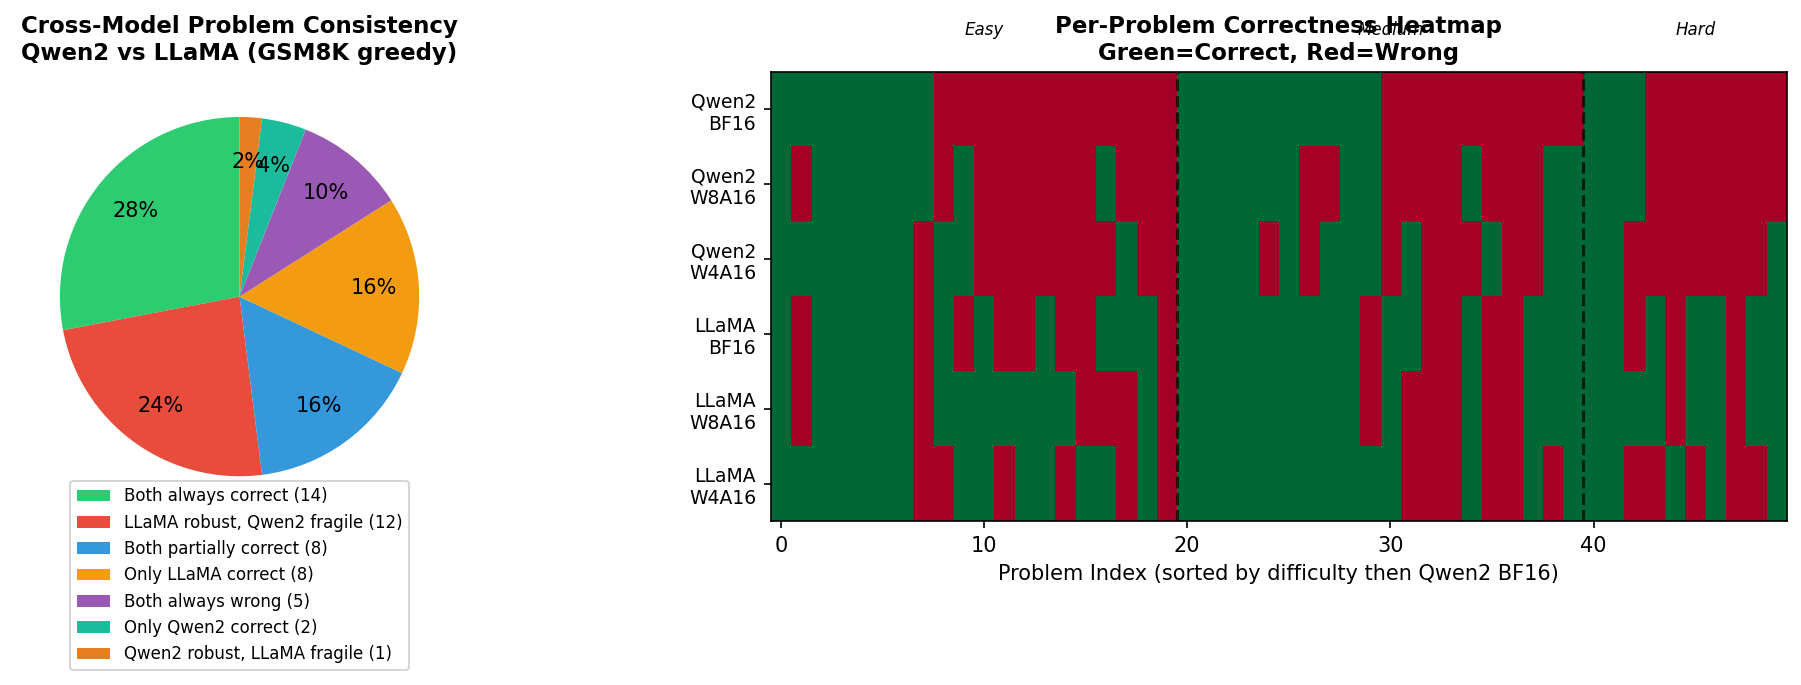

Figure saved


In [11]:
# ── CELL 10: Cross-model consistency plot ─────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: cross-model category pie chart
cross_counts = merged['cross_model_category'].value_counts()
colors_pie   = ['#2ecc71', '#e74c3c', '#3498db', '#f39c12', '#9b59b6',
                '#1abc9c', '#e67e22']

wedges, texts, autotexts = axes[0].pie(
    cross_counts.values,
    labels=None,
    autopct='%1.0f%%',
    colors=colors_pie[:len(cross_counts)],
    startangle=90,
    pctdistance=0.75
)
axes[0].legend(wedges, [f'{k} ({v})' for k, v in cross_counts.items()],
               loc='lower center', bbox_to_anchor=(0.5, -0.35),
               fontsize=8, ncol=1)
axes[0].set_title('Cross-Model Problem Consistency\nQwen2 vs LLaMA (GSM8K greedy)',
                   fontsize=11, fontweight='bold')

# Right: heatmap showing per-problem correctness
# Each row = one problem, columns = (model, bitwidth) combinations
cols      = ['Q_BF16', 'Q_W8A16', 'Q_W4A16', 'L_BF16', 'L_W8A16', 'L_W4A16']
col_labels = ['Qwen2\nBF16', 'Qwen2\nW8A16', 'Qwen2\nW4A16',
               'LLaMA\nBF16', 'LLaMA\nW8A16', 'LLaMA\nW4A16']

# Sort by difficulty then by Qwen2 BF16 correctness
diff_order  = {'easy': 0, 'medium': 1, 'hard': 2}
merged_sort = merged.copy()
merged_sort['diff_order'] = merged_sort['difficulty'].map(diff_order)
merged_sort = merged_sort.sort_values(['diff_order', 'Q_BF16'], ascending=[True, False])

heatmap_data = merged_sort[cols].astype(int).values
im = axes[1].imshow(heatmap_data.T, aspect='auto', cmap='RdYlGn',
                     vmin=0, vmax=1, interpolation='none')
axes[1].set_yticks(range(len(cols)))
axes[1].set_yticklabels(col_labels, fontsize=9)
axes[1].set_xlabel('Problem Index (sorted by difficulty then Qwen2 BF16)', fontsize=10)
axes[1].set_title('Per-Problem Correctness Heatmap\nGreen=Correct, Red=Wrong',
                   fontsize=11, fontweight='bold')

# Add vertical lines to separate difficulty groups
n_easy   = len(merged_sort[merged_sort['difficulty']=='easy'])
n_medium = len(merged_sort[merged_sort['difficulty']=='medium'])
axes[1].axvline(n_easy - 0.5, color='black', linewidth=1.5, linestyle='--', alpha=0.7)
axes[1].axvline(n_easy + n_medium - 0.5, color='black', linewidth=1.5, linestyle='--', alpha=0.7)
axes[1].text(n_easy/2, -1, 'Easy', ha='center', fontsize=8, style='italic')
axes[1].text(n_easy + n_medium/2, -1, 'Medium', ha='center', fontsize=8, style='italic')
axes[1].text(n_easy + n_medium + (50-n_easy-n_medium)/2, -1, 'Hard',
             ha='center', fontsize=8, style='italic')

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/cross_model_consistency.pdf', dpi=300, bbox_inches='tight')
plt.savefig(f'{OUTPUT_DIR}/cross_model_consistency.png', dpi=300, bbox_inches='tight')
plt.show()
print('Figure saved')

In [12]:
# ── CELL 11: SC hurt problems deep dive ───────────────────────────────────────
# Which specific problems did SC hurt at W4A16 for Qwen2?
# These are the clearest examples of systematic quantization error

sc_hurt_w4 = qwen2_pivot[
    qwen2_pivot['sc_effect_W4A16'] == 'SC Hurt'
][['problem_id', 'difficulty', 'W4A16_greedy',
   'sc_effect_BF16', 'sc_effect_W8A16', 'sc_effect_W4A16',
   'greedy_category']]

print(f'Problems where SC HURT Qwen2 at W4A16: {len(sc_hurt_w4)}')
print()
if len(sc_hurt_w4) > 0:
    print(sc_hurt_w4.to_string(index=False))
    print()
    print('Difficulty breakdown of SC-hurt problems:')
    print(sc_hurt_w4['difficulty'].value_counts().to_string())
    print()
    print('Were these problems already fragile under quantization?')
    print(sc_hurt_w4['greedy_category'].value_counts().to_string())
else:
    print('No SC-hurt problems detected at W4A16')

print()
print('Compare: SC hurt problems at BF16 and W8A16:')
for bw in ['BF16', 'W8A16']:
    hurt = qwen2_pivot[qwen2_pivot[f'sc_effect_{bw}'] == 'SC Hurt']
    print(f'  {bw}: {len(hurt)} problems hurt by SC')

Problems where SC HURT Qwen2 at W4A16: 10

 problem_id difficulty  W4A16_greedy sc_effect_BF16 sc_effect_W8A16 sc_effect_W4A16          greedy_category
        473       easy          True     Both Wrong      Both Wrong         SC Hurt Improved by Quantization
        433       easy          True   Both Correct    Both Correct         SC Hurt                   Robust
        359     medium          True      SC Helped       SC Helped         SC Hurt Improved by Quantization
        872     medium          True   Both Correct    Both Correct         SC Hurt                   Robust
        586     medium          True      SC Helped      Both Wrong         SC Hurt Improved by Quantization
        438     medium          True   Both Correct    Both Correct         SC Hurt                   Robust
        227     medium          True      SC Helped    Both Correct         SC Hurt Improved by Quantization
       1202     medium          True      SC Helped         SC Hurt         SC Hurt I

In [13]:
# ── CELL 12: Save all results ─────────────────────────────────────────────────

# Save full problem-level table for Qwen2
qwen2_pivot.to_csv(f'{OUTPUT_DIR}/qwen2_problem_consistency.csv', index=False)

# Save cross-model merged table
merged.to_csv(f'{OUTPUT_DIR}/cross_model_consistency.csv', index=False)

# Save SC effect summary
sc_rows = []
for bw in ['BF16', 'W8A16', 'W4A16']:
    for model, model_sum in [('Qwen2', sc_summary), ('LLaMA', llama_sc_summary)]:
        for eff in ['SC Helped', 'SC Hurt', 'Both Correct', 'Both Wrong']:
            sc_rows.append({
                'model': model, 'bitwidth': bw,
                'effect': eff, 'count': model_sum[bw].get(eff, 0)
            })
pd.DataFrame(sc_rows).to_csv(f'{OUTPUT_DIR}/sc_effect_summary.csv', index=False)

print('Files saved:')
for f in sorted(os.listdir(OUTPUT_DIR)):
    size = os.path.getsize(f'{OUTPUT_DIR}/{f}')
    print(f'  {f}  ({size/1024:.1f} KB)')
print()
print('Copy consistency_outputs/ → 05_results/figures/ in submission folder')

Files saved:
  cross_model_consistency.csv  (4.0 KB)
  cross_model_consistency.pdf  (36.1 KB)
  cross_model_consistency.png  (241.9 KB)
  problem_categories.pdf  (31.3 KB)
  problem_categories.png  (199.7 KB)
  qwen2_problem_consistency.csv  (5.0 KB)
  sc_effect_by_bitwidth.pdf  (29.8 KB)
  sc_effect_by_bitwidth.png  (145.5 KB)
  sc_effect_summary.csv  (0.6 KB)

Copy consistency_outputs/ → 05_results/figures/ in submission folder


In [14]:
# ── CELL 13: Paper-ready summary ──────────────────────────────────────────────

print('='*65)
print('PROBLEM CONSISTENCY SUMMARY — for paper')
print('='*65)
print()
print('Qwen2 1.5B problem categories (greedy, GSM8K 50 problems):')
cat_counts = qwen2_pivot['greedy_category'].value_counts()
for cat, count in cat_counts.items():
    print(f'  {cat:<35}: {count} ({count/50*100:.0f}%)')

print()
print('SC effect on Qwen2 (problems changed by SC vs greedy):')
print(f'{"Effect":<20} {"BF16":>8} {"W8A16":>8} {"W4A16":>8}')
print('-'*46)
for eff in ['SC Helped', 'SC Hurt', 'Both Correct', 'Both Wrong']:
    vals = [sc_summary[bw].get(eff, 0) for bw in ['BF16','W8A16','W4A16']]
    print(f'{eff:<20} {vals[0]:>8} {vals[1]:>8} {vals[2]:>8}')

print()
print('SC effect on LLaMA (problems changed by SC vs greedy):')
print(f'{"Effect":<20} {"BF16":>8} {"W8A16":>8} {"W4A16":>8}')
print('-'*46)
for eff in ['SC Helped', 'SC Hurt', 'Both Correct', 'Both Wrong']:
    vals = [llama_sc_summary[bw].get(eff, 0) for bw in ['BF16','W8A16','W4A16']]
    print(f'{eff:<20} {vals[0]:>8} {vals[1]:>8} {vals[2]:>8}')

print()
print('KEY FINDINGS:')
q_hurt_w4 = sc_summary['W4A16'].get('SC Hurt', 0)
l_hurt_w4 = llama_sc_summary['W4A16'].get('SC Hurt', 0)
q_help_w4 = sc_summary['W4A16'].get('SC Helped', 0)
l_help_w4 = llama_sc_summary['W4A16'].get('SC Helped', 0)
print(f'  Qwen2 W4A16: SC hurts {q_hurt_w4} problems, helps {q_help_w4}')
print(f'  LLaMA W4A16: SC hurts {l_hurt_w4} problems, helps {l_help_w4}')
print()
print('  --> If Qwen2 SC Hurt >> LLaMA SC Hurt at W4A16:')
print('      Confirms systematic error hypothesis for Qwen2')
print('      Voting amplifies wrong answers when errors are correlated')

PROBLEM CONSISTENCY SUMMARY — for paper

Qwen2 1.5B problem categories (greedy, GSM8K 50 problems):
  Always Wrong                       : 19 (38%)
  Robust                             : 15 (30%)
  Improved by Quantization           : 10 (20%)
  Fragile at W8A16                   : 3 (6%)
  Fragile at W4A16                   : 3 (6%)

SC effect on Qwen2 (problems changed by SC vs greedy):
Effect                   BF16    W8A16    W4A16
----------------------------------------------
SC Helped                   8        5        4
SC Hurt                     1        2       10
Both Correct               20       21       15
Both Wrong                 21       22       21

SC effect on LLaMA (problems changed by SC vs greedy):
Effect                   BF16    W8A16    W4A16
----------------------------------------------
SC Helped                   9        7        9
SC Hurt                     2        2        0
Both Correct               32       34       33
Both Wrong                